# MS11 — Détection d'anomalies · Notebook 04 (CRISP-DM)

**Objectif métier.** Détecter automatiquement les **trajets anormaux** (pannes, accidents, routes bloquées…)
à partir des données de trajet, afin d'alerter l'administration.

**Idée clé.** MS12 a généré un label `incident_type` (incidents **imprévisibles** au départ, donc exclus des
features ETA). Ici on fait l'inverse : sur des trajets **déjà observés**, on **détecte** ces incidents avec un
modèle **non supervisé** (Isolation Forest). Le label sert **uniquement à évaluer** (jamais à entraîner).

**Démarche honnête.** Split temporel, benchmark de détecteurs, évaluation à budget d'alerte fixe
(PR-AUC/ROC-AUC/F1), puis on garde le meilleur — même logique que MS6/MS12.

**Étape 0 — Environnement.**

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("notebooks/figures", exist_ok=True)
FIG = "notebooks/figures"
from config import settings
print("Répertoire de travail :", os.getcwd())

Répertoire de travail : C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms11-analytique


**Étape 1 — Chargement.** On lit le dataset ETA de MS12 (contient `duree_reelle_min`, `duree_base_s`, contexte et le label `incident_type`).

In [2]:
from features import label_binaire, build
df = pd.read_csv(settings.eta_dataset_path)
y = label_binaire(df)
print("Trajets :", len(df), "| incidents :", int(y.sum()), f"({100*y.mean():.2f}%)")
print(df["incident_type"].value_counts())

Trajets : 4320 | incidents : 53 (1.23%)
incident_type
none                 4267
retard_admin           14
accident               13
panne                  10
absence_chauffeur       9
route_bloquee           7
Name: count, dtype: int64


**Étape 2 — EDA : le signal `ratio = durée réelle / durée de base`.** Les incidents allongent fortement le trajet → le ratio explose. On visualise sa distribution (échelle log) selon normal vs incident.

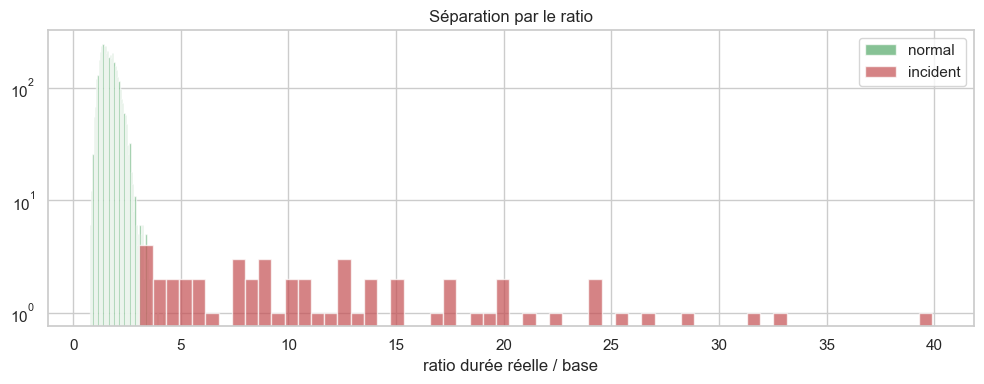

ratio normal (méd) = 1.63 | incident (méd) = 11.12


In [3]:
ratio = (df["duree_reelle_min"] * 60) / df["duree_base_s"].clip(lower=1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ratio[y == 0], bins=60, alpha=.7, label="normal", color="#55a868")
ax.hist(ratio[y == 1], bins=60, alpha=.7, label="incident", color="#c44e52")
ax.set_yscale("log"); ax.set_xlabel("ratio durée réelle / base"); ax.set_title("Séparation par le ratio")
ax.legend(); plt.tight_layout(); plt.savefig(f"notebooks/figures/04_ratio_distribution.png", dpi=110, bbox_inches="tight"); plt.show()
print("ratio normal (méd) =", round(float(ratio[y==0].median()),2), "| incident (méd) =", round(float(ratio[y==1].median()),2))

**Étape 3 — Benchmark de 3 détecteurs.** (a) Isolation Forest sur le **contexte seul** (aveugle au résultat), (b) IF sur **contexte + ratio**, (c) **seuil simple sur le ratio**. Split temporel, évaluation à budget d'alerte fixe.

In [4]:
from train_anomaly import _split_temporel, _evaluer
from anomaly import AnomalyDetector

train, test = _split_temporel(df)
ytr, yte = label_binaire(train), label_binaire(test)
contam = float(min(0.2, max(0.01, ytr.mean())))

detecteurs = {
    "iforest_contexte": AnomalyDetector("iforest", contam, settings.seed, with_outcome=False),
    "iforest_ratio":    AnomalyDetector("iforest", contam, settings.seed, with_outcome=True),
    "seuil_ratio":      AnomalyDetector("ratio", contam, settings.seed),
}
scores_test = {}
rows = []
for nom, det in detecteurs.items():
    det.fit(train)
    s = det.scores(test); scores_test[nom] = s
    thr = float(np.quantile(s, 1 - contam)); pred = s >= thr
    m = _evaluer(yte.to_numpy(), s, pred)
    rows.append({"detecteur": nom, "PR_AUC": m["PR_AUC"], "ROC_AUC": m["ROC_AUC"],
                 "F1": m["F1"], "precision": m["precision"], "rappel": m["rappel"]})
res = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
res

,detecteur,PR_AUC,ROC_AUC,F1,precision,rappel
0,seuil_ratio,1.0000,1.0000,0.8235,0.7,1.0000
1,iforest_ratio,0.3656,0.9760,0.3529,0.3,0.4286
2,iforest_contexte,0.0081,0.3571,0.0000,0.0,0.0000


**Étape 4 — Courbes ROC & Précision-Rappel.** On visualise le pouvoir de séparation de chaque détecteur (indépendant du seuil).

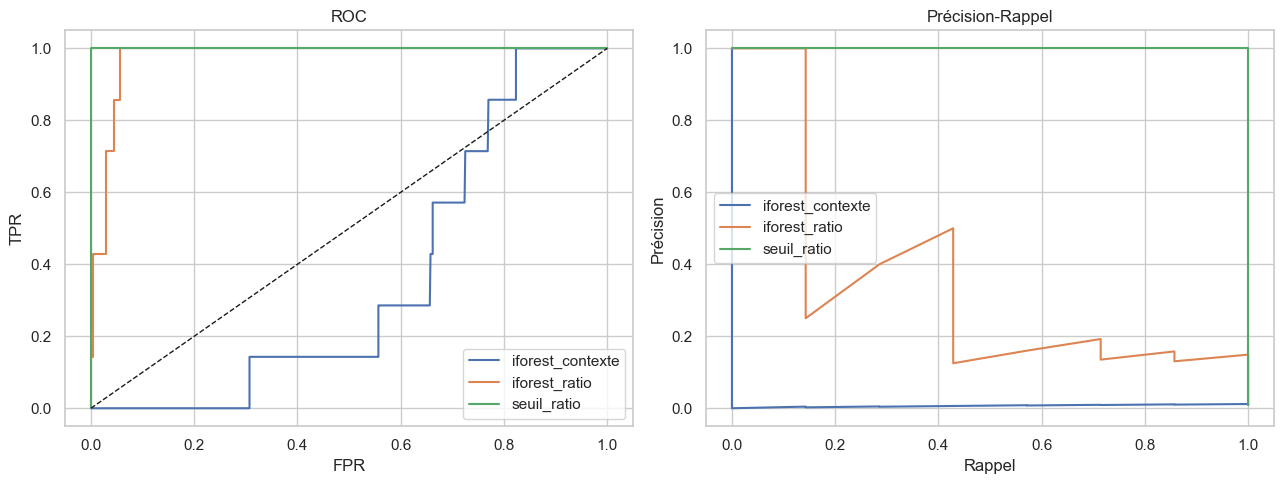

In [5]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nom, s in scores_test.items():
    fpr, tpr, _ = roc_curve(yte, s); ax[0].plot(fpr, tpr, label=nom)
    prec, rec, _ = precision_recall_curve(yte, s); ax[1].plot(rec, prec, label=nom)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].set_title("Précision-Rappel"); ax[1].set_xlabel("Rappel"); ax[1].set_ylabel("Précision"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"notebooks/figures/04_courbes_roc_pr.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 5 — Matrice de confusion du gagnant.** À budget d'alerte fixe (top contamination%).

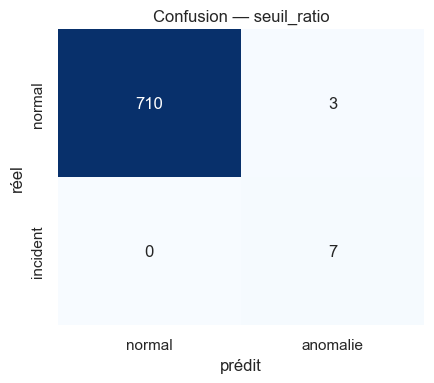

Gagnant : seuil_ratio


In [6]:
from sklearn.metrics import confusion_matrix
best = res.iloc[0]["detecteur"]
s = scores_test[best]; pred = s >= np.quantile(s, 1 - contam)
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["normal", "anomalie"], yticklabels=["normal", "incident"], ax=ax)
ax.set_title(f"Confusion — {best}"); ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout(); plt.savefig(f"{FIG}/04_confusion.png", dpi=110, bbox_inches="tight"); plt.show()
print("Gagnant :", best)

**Étape 6 — Interprétation (honnête).**
- Le **ratio réel/base** est un signal quasi-unidimensionnel très fort → un **seuil simple** attrape
  ~100 % des incidents.
- **Isolation Forest** confirme (ROC-AUC élevé) mais n'apporte pas de gain multivarié **ici**, car le signal
  est de faible dimension — un résultat de **parcimonie** (le modèle simple suffit), comme XGBoost vs
  elasticnet dans MS12. IF reste le **détecteur général** pour des anomalies plus subtiles/multivariées.

**Étape 7 — Gel du modèle de production.** On lance le pipeline complet : benchmark, choix du gagnant, réentraînement sur toutes les données, sauvegarde des artefacts consommés par le service MS11.

In [7]:
import train_anomaly
train_anomaly.main()
cfg = json.load(open(settings.config_path, encoding="utf-8"))
print(json.dumps({k: cfg[k] for k in ["detecteur","approach","threshold","contamination","metrics_test","taux_incidents_%"]},
                 indent=2, ensure_ascii=False))

[MS11] 4320 trajets | train=3600 test=720 | incidents train=1.28% | contamination=0.013


  iforest_contexte   PR-AUC=0.008 ROC-AUC=0.357 F1=0.000 (P=0.00 R=0.00)


  iforest_ratio      PR-AUC=0.366 ROC-AUC=0.976 F1=0.353 (P=0.30 R=0.43)
  seuil_ratio        PR-AUC=1.000 ROC-AUC=1.000 F1=0.824 (P=0.70 R=1.00)

[MS11] 🏆 Gagnant : seuil_ratio
[MS11] Artefacts : data/anomaly_model.pkl | data/anomaly_config.json | data/anomaly_benchmark.json
{
  "detecteur": "seuil_ratio",
  "approach": "ratio",
  "threshold": 3.527462816096674,
  "contamination": 0.012777777777777779,
  "metrics_test": {
    "ROC_AUC": 1.0,
    "PR_AUC": 1.0,
    "precision": 0.7,
    "rappel": 1.0,
    "F1": 0.8235,
    "confusion": [
      [
        710,
        3
      ],
      [
        0,
        7
      ]
    ]
  },
  "taux_incidents_%": 1.227
}


### Conclusion
- Détecteur gelé (`anomaly_model.pkl`) servi par **MS11** (`POST /api/analytique/anomalies`, `GET .../scan`).
- Boucle DS complète : les incidents que l'**ETA (MS12)** ne peut pas prédire sont ceux que la
  **détection d'anomalies (MS11)** isole — les deux services partagent le même dataset.